# Education Disparities and National Life Evaluation
## Measurement, prosperity adjustment and evidence within countries

**Mobin Seyedmohammadi — independent research study, 12 November 2026**

This study examines socioeconomic disparities in secondary-school completion and their association with national life evaluation using a recent cross section and a repeated-country panel.

AI tools assisted with code and writing. This notebook is exploratory and is not a preregistered analysis.

The paper and notebook distinguish measurement, conditional association and prediction. The complete raw-data snapshots are bundled, so no additional download is necessary.

## 1. A reproducible starting point

Install `requirements.txt` in a Python 3.12 environment. Run this notebook from its directory or the project root. The first cell identifies the root and rebuilds all scientific outputs when `RUN_FULL_PIPELINE=True`. No network requests occur. For a quick reading of the supplied outputs, change that flag to `False`.

The scientific functions live in inspectable modules under `src/`. This prevents the paper, notebook and command-line workflow from drifting into different analyses.

In [1]:
from pathlib import Path
import os, sys, json, runpy

PROJECT = Path.cwd()
if not (PROJECT / 'src').is_dir():
    PROJECT = PROJECT.parent
assert (PROJECT / 'src/analysis.py').is_file(), 'Open this notebook inside the project folder.'
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

RUN_FULL_PIPELINE = True
if RUN_FULL_PIPELINE:
    for module in ['src.analysis', 'src.measurement', 'src.panel', 'src.simulation', 'src.verify', 'src.make_report']:
        print('Rebuilding', module)
        runpy.run_module(module, run_name='__main__')
print('Project:', PROJECT)

Rebuilding src.analysis
{
  "sample": {
    "happiness_countries": 147,
    "wide_countries": 177,
    "paired_recent_education_countries": 87,
    "happiness_with_education": 70,
    "with_education_and_gini": 65,
    "primary_countries": 65,
    "expanded_countries": 79,
    "regions_in_primary": 7
  },
  "primary": {
    "model": "M5",
    "label": "M5",
    "term": "gap10",
    "n": 65,
    "estimate": 0.054027991560167465,
    "se_hc3": 0.04715518261408162,
    "ci_low": -0.04029641751946472,
    "ci_high": 0.14835240063979965,
    "p_value": 0.2564484253718185,
    "r2": 0.6461461468165637,
    "adj_r2": 0.622555889937668
  },
  "cv_paired": {
    "rmse_difference_full_minus_baseline": 0.0034874641362375113,
    "split_sd": 0.00729413125643626,
    "min_across_splits": -0.005657199147401704,
    "max_across_splits": 0.025459218602869038,
    "repeats_full_better": 7,
    "repeats": 20,
    "interpretation": "Variation across reused random partitions, not a sampling confidence int

<frozen runpy>:128: RuntimeWarning: 'src.analysis' found in sys.modules after import of package 'src', but prior to execution of 'src.analysis'; this may result in unpredictable behaviour


In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display, Image, Markdown
from src.analysis import FULL, BASE, fit, verify_inputs
from src.panel import panel_fit

T = PROJECT / 'outputs/tables'
P = PROJECT / 'data/processed'
F = PROJECT / 'outputs/figures'
d = pd.read_csv(P / 'analysis_primary.csv')
panel = pd.read_csv(P / 'panel_within_sample.csv')
results = json.loads((PROJECT / 'outputs/results.json').read_text())
panel_results = json.loads((PROJECT / 'outputs/panel_results.json').read_text())
def show(name, width=950):
    display(Image(filename=str(F / (name + '.png')), width=width))
def table(name):
    return pd.read_csv(T / name)
display(pd.Series(results['sample'], name='Count'))

happiness_countries                  147
wide_countries                       177
paired_recent_education_countries     87
happiness_with_education              70
with_education_and_gini               65
primary_countries                     65
expanded_countries                    79
regions_in_primary                     7
Name: Count, dtype: int64

## 2. Source provenance and data management

The original WIDE, Gini and happiness snapshots have unknown historical extraction dates. New real PPP GDP observations were downloaded on 12 November 2026 and contain later revisions. We describe historical relationships retrospectively, rather than forecasting with vintage information.

Country joins use ISO3 codes and explicit aliases. Conflicting completion estimates at a country-survey-year-group key invalidate the entire survey. Identical point estimates collapse. All five SES quintiles and a national total must exist in a selected survey. Each analysis country has exactly one selected observation per eligible period.

In [3]:
manifest = verify_inputs()
display(pd.DataFrame(manifest['files'])[['path', 'bytes', 'provider', 'provenance_note']])
display(table('excluded_ambiguous_surveys.csv'))
display(pd.read_csv(P / 'country_crosswalk.csv').head(12))

,path,bytes,provider,provenance_note
0,data/raw/WIDE.csv.gz,17364231,"UNESCO GEM Report and UIS, World Inequality Da...",Archived source snapshot; historical extractio...
1,data/raw/GINI.csv,74864,"World Bank, SI.POV.GINI",Archived source snapshot. Original extraction ...
2,data/raw/happiness2025.xlsx,148164,"World Happiness Report 2025, Figure 2.1 data",Archived source workbook. Endpoint 2024 means ...
3,data/raw/gdp_ppp_2022_2024.json,198457,"World Bank, NY.GDP.PCAP.PP.KD",Downloaded 2026-11-12. API last update 2026-11...
4,data/raw/gdp_panel_2016_2018.json,198508,"World Bank, NY.GDP.PCAP.PP.KD",Downloaded 2026-11-12. API last update 2026-11...
5,data/raw/gdp_panel_2019_2021.json,198531,"World Bank, NY.GDP.PCAP.PP.KD",Downloaded 2026-11-12. API last update 2026-11...
6,data/raw/gdp_panel_2013_2015.json,198502,"World Bank, NY.GDP.PCAP.PP.KD",Downloaded 2026-11-12. API last update 2026-11...


,iso_code,survey,year
0,AUS,SIH,2014
1,COL,GEIH,2011
2,COL,GEIH,2012
3,COL,GEIH,2013
4,COL,GEIH,2014
5,RUS,RLMS-HSE,2020
6,RUS,RLMS-HSE,2021


,happiness_name,iso_code,method
0,Finland,FIN,ISO exact lookup
1,Denmark,DNK,ISO exact lookup
2,Iceland,ISL,ISO exact lookup
3,Sweden,SWE,ISO exact lookup
4,Netherlands,NLD,ISO exact lookup
5,Costa Rica,CRI,ISO exact lookup
6,Norway,NOR,ISO exact lookup
7,Israel,ISR,ISO exact lookup
8,Luxembourg,LUX,ISO exact lookup
9,Mexico,MEX,ISO exact lookup


In [4]:
audit = pd.read_csv(P / 'country_audit_primary.csv')
display(audit[['iso_code', 'country', 'education_year', 'gini_year', 'included', 'exclusion_reasons']].head(20))
display(table('sample_selection.csv'))
display(table('coverage_by_income_group.csv'))

,iso_code,country,education_year,gini_year,included,exclusion_reasons
0,FIN,Finland,NaN,2022.0,False,no eligible paired education survey
1,DNK,Denmark,NaN,2022.0,False,no eligible paired education survey
2,ISL,Iceland,NaN,2018.0,False,no eligible paired education survey
3,SWE,Sweden,NaN,2022.0,False,no eligible paired education survey
4,NLD,Netherlands,NaN,2021.0,False,no eligible paired education survey
5,CRI,Costa Rica,2021.0,2024.0,True,NaN
6,NOR,Norway,NaN,2022.0,False,no eligible paired education survey
7,ISR,Israel,NaN,2021.0,False,no eligible paired education survey
8,LUX,Luxembourg,NaN,2022.0,False,no eligible paired education survey
9,MEX,Mexico,2020.0,2022.0,True,NaN


,variable,included_n,excluded_n,included_mean,excluded_mean,standardized_mean_difference
0,ladder,65,82,5.321677,5.781488,-0.406495
1,log_gdp,65,79,9.158288,10.120875,-0.932690
2,gini,65,56,37.870769,34.260714,0.511465


,income_group,False,True
0,High income,41,7
1,Low income,5,12
2,Lower middle income,17,24
3,Not classified,1,0
4,Upper middle income,14,22
5,NaN,4,0


## 3. What does educational inequality mean here?

The absolute gap is `100 × (Q5 − Q1)` percentage points. The relative gap is `(Q5 − Q1) / ((Q5 + Q1)/2)`. The same absolute difference receives a different relative score when the groups have a different overall attainment level.

Neither is a universal definition of educational inequality. The selected WIDE column measures a specific upper-secondary completion cohort, and its SES groups are source-specific rankings. They are not uniformly predetermined circumstances. We therefore avoid calling this a formal inequality-of-opportunity estimate.

,Q1,Q5,absolute_gap_pp,relative_gap
0,0.1,0.2,10.0,0.666667
1,0.8,0.9,10.0,0.117647


,gap10,relative_gap,completion10,log_gdp,ladder
gap10,1.000,0.477,-0.300,-0.237,-0.095
relative_gap,0.477,1.000,-0.944,-0.795,-0.644
completion10,-0.300,-0.944,1.000,0.825,0.708
log_gdp,-0.237,-0.795,0.825,1.000,0.769
ladder,-0.095,-0.644,0.708,0.769,1.000


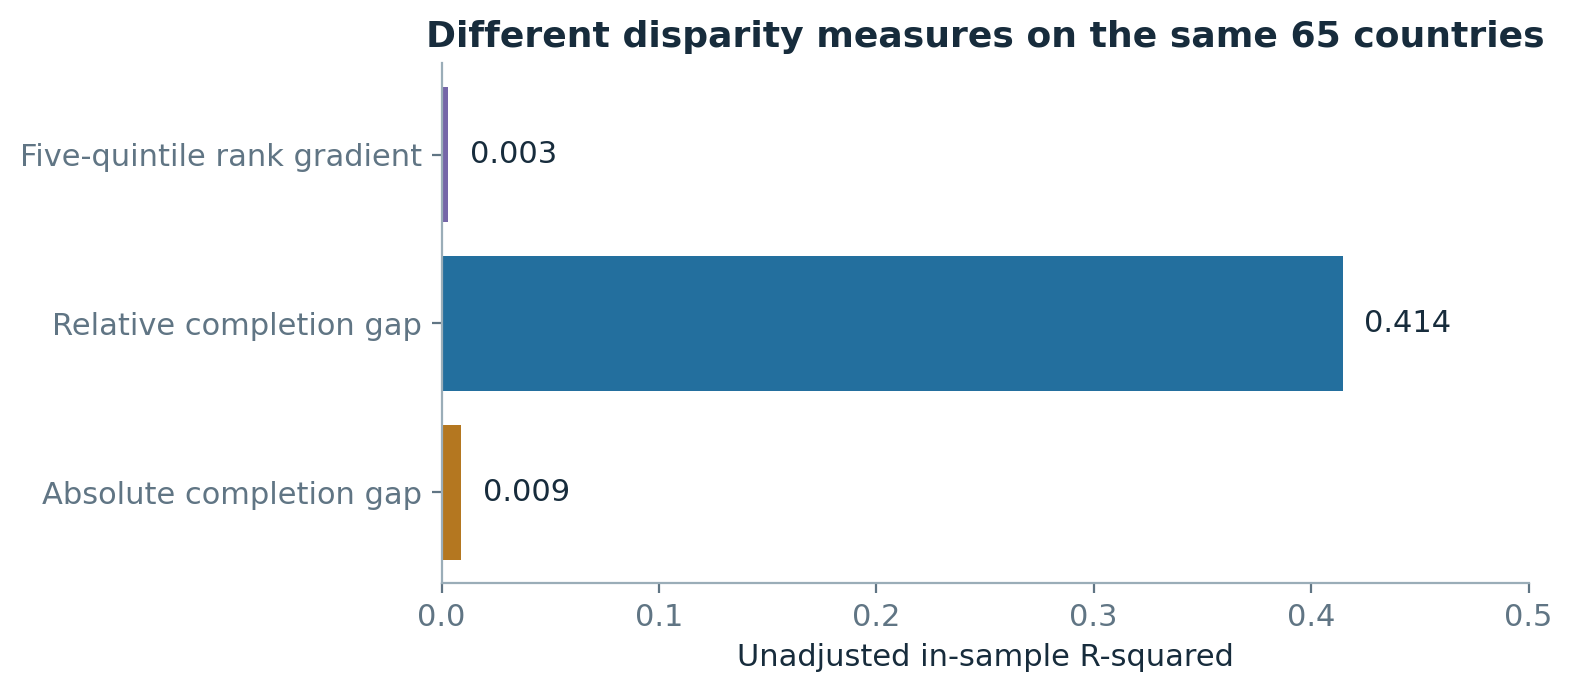

In [5]:
example = pd.DataFrame({'Q1': [.10, .80], 'Q5': [.20, .90]})
example['absolute_gap_pp'] = 100 * (example.Q5 - example.Q1)
example['relative_gap'] = (example.Q5 - example.Q1) / ((example.Q5 + example.Q1) / 2)
display(example)
assert np.allclose(d.gap10, (d['Quintile 5'] - d['Quintile 1']) * 10)
display(d[['gap10', 'relative_gap', 'completion10', 'log_gdp', 'ladder']].corr().round(3))
show('13_measurement_comparison')

## 4. The recent cross section

Every nested comparison uses the same complete-case countries. The full specification includes the 10 pp education gap, log real PPP GDP/person, 10 pp national completion, and 10-point Gini. HC3 covariance with a t reference addresses heteroskedasticity and leverage under a working model. It does not solve omitted variables, dependence between countries or causal identification.

,model,label,term,n,estimate,se_hc3,ci_low,ci_high,p_value,r2,adj_r2
0,M1,Education gap only,gap10,65,-0.055241,0.067993,-0.191115,0.080633,0.419595,0.009018,-0.006712
1,M2,Gini only,gini10,65,0.249660,0.191184,-0.132391,0.631711,0.196347,0.027145,0.011702
2,M3,Gap + prosperity,gap10,65,0.053860,0.044863,-0.035820,0.143540,0.234492,0.599801,0.586891
3,M4,Gap + prosperity + attainment,gap10,65,0.071250,0.046177,-0.021085,0.163586,0.128003,0.622311,0.603736
4,M5,Gap + prosperity + attainment + Gini,gap10,65,0.054028,0.047155,-0.040296,0.148352,0.256448,0.646146,0.622556


,coefficient,HC3_SE,p,CI_low,CI_high
const,-1.676359,1.399334,0.235640,-4.475443,1.122725
log_gdp,0.591652,0.161969,0.000546,0.267667,0.915638
completion10,0.097955,0.052087,0.064883,-0.006235,0.202144
gini10,0.238379,0.150445,0.118339,-0.062556,0.539314
gap10,0.054028,0.047155,0.256448,-0.040296,0.148352


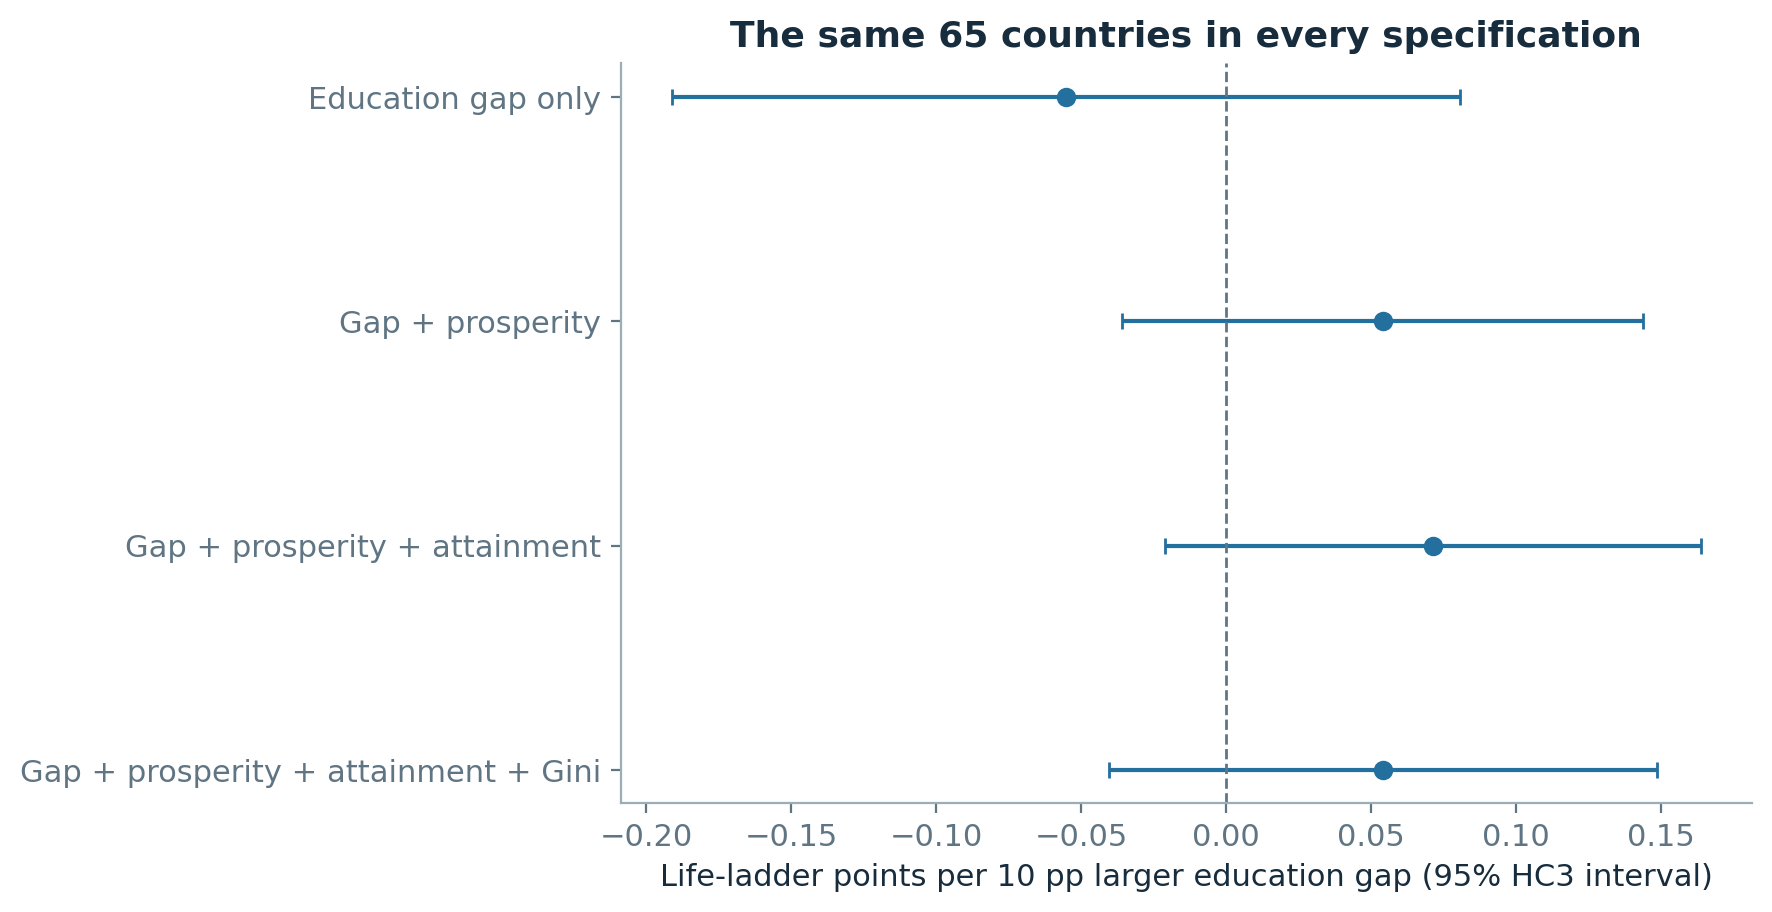

In [6]:
m = fit(d, FULL)
display(table('model_ladder.csv'))
display(pd.DataFrame({'coefficient': m.params, 'HC3_SE': m.bse, 'p': m.pvalues}).join(m.conf_int().rename(columns={0:'CI_low', 1:'CI_high'})))
show('03_model_ladder')

## 5. The added-variable identity and diagnostic evidence

Residualize both the education gap and life evaluation on the same controls. The residual-on-residual slope equals the education coefficient in the full regression. This is an algebraic identity, not a new identification strategy.

Model checks and influence diagnostics remain visible even when their outcomes look reassuring. Country deletion is a sensitivity exercise, not a method of selecting an attractive result.

FWL slope: 0.05402799156016771


breusch_pagan_lm_p                                                     0.76529
reset_hc3_p                                                           0.245379
max_vif                                                               3.251586
condition_number_unscaled                                           176.954453
flagged_countries            [DR Congo, Egypt, Kyrgyzstan, Mozambique, Nami...
fwl_slope_check                                                       0.054028
residual_df                                                               60.0
dtype: object

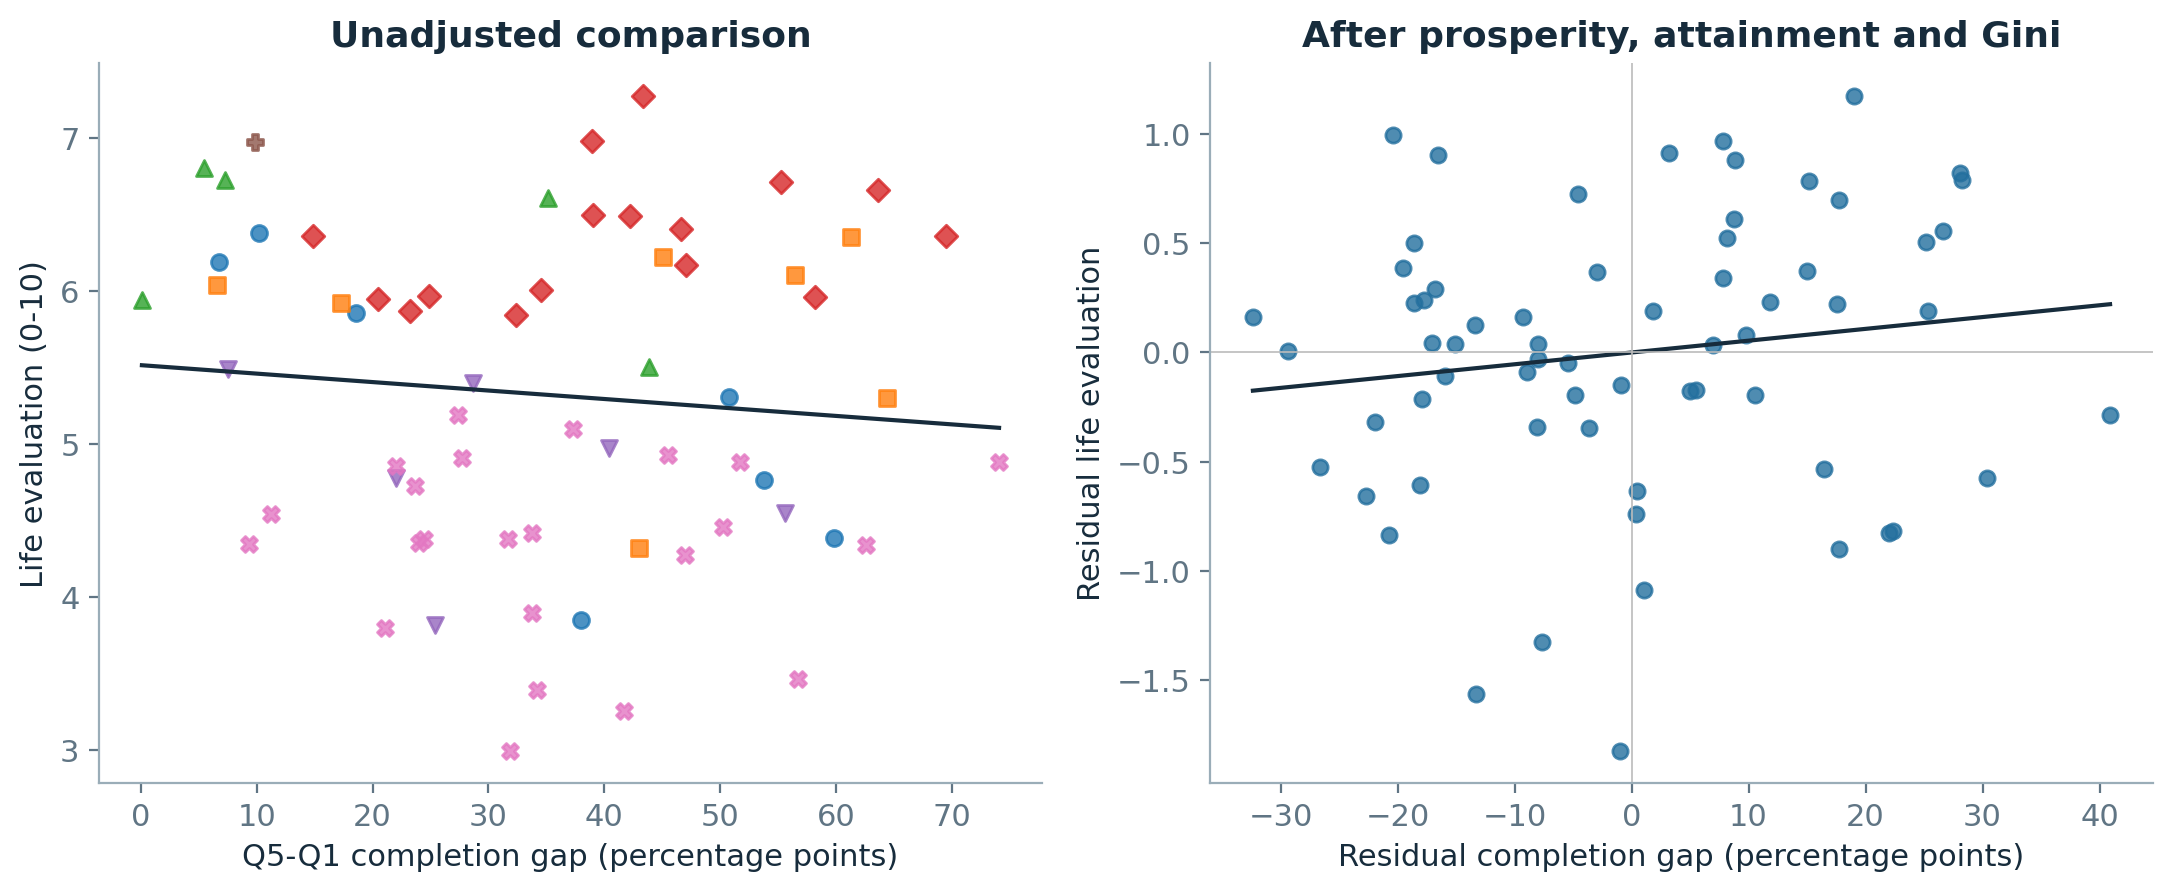

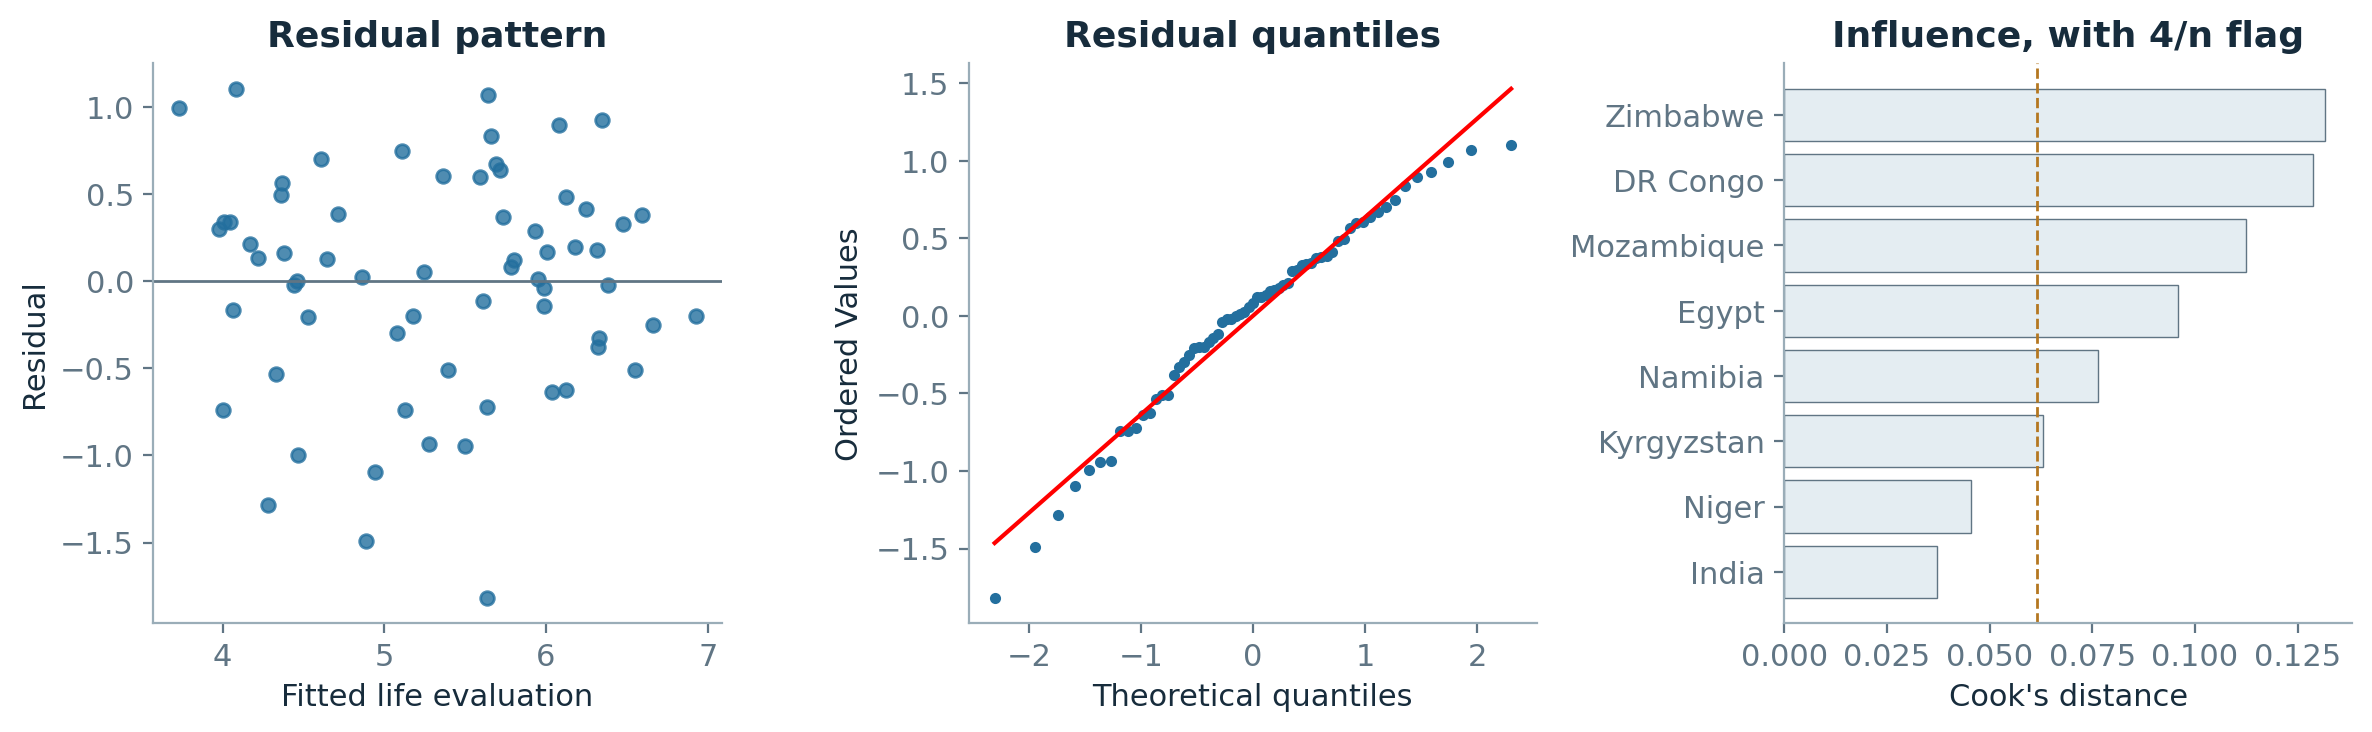

In [7]:
controls = sm.add_constant(d[BASE], has_constant='add')
gap_resid = sm.OLS(d.gap10, controls).fit().resid
life_resid = sm.OLS(d.ladder, controls).fit().resid
fwl_slope = np.dot(gap_resid, life_resid) / np.dot(gap_resid, gap_resid)
assert np.isclose(fwl_slope, m.params.gap10, atol=1e-10)
print('FWL slope:', fwl_slope)
display(pd.Series(results['diagnostics']))
show('02_raw_and_adjusted')
show('06_diagnostics')

## 6. A repeated-country design without overlapping outcome windows

The longitudinal analysis matches education in 2010–2012 to life evaluation in 2013–2015, then advances both disjoint blocks by three years. Education precedes the start of its outcome window by 1–3 years. No survey is reused across periods. Country effects absorb stable additive country attributes, and period effects absorb common shifts.

These are repeated aggregate country observations. They do not follow the same individuals, and temporal ordering does not turn the education gap into an exogenous treatment.

In [8]:
display(table('panel_sample_flow.csv'))
display(table('panel_coverage.csv'))
assert not panel.duplicated(['iso_code', 'endpoint']).any()
assert not panel.duplicated(['iso_code', 'survey', 'education_year']).any()
assert panel.education_lag.between(1, 3).all()
display(panel[['iso_code', 'country', 'endpoint', 'education_year', 'survey', 'education_lag']].head(18))

,endpoint,happiness_units_after_territory_exclusions,with_prior_education,complete_rows
0,2015,155,80,78
1,2018,155,67,65
2,2021,145,46,46
3,2024,147,37,37


,periods,countries
0,2,30
1,3,22
2,4,18


,iso_code,country,endpoint,education_year,survey,education_lag
0,AFG,Afghanistan,2015,2011.0,MICS,2.0
1,AFG,Afghanistan,2018,2015.0,DHS,1.0
2,ARM,Armenia,2015,2011.0,DHS,2.0
3,ARM,Armenia,2021,2018.0,ILCS,1.0
4,AUS,Australia,2015,2010.0,SIH,3.0
5,AUS,Australia,2021,2018.0,SIH,1.0
6,BEN,Benin,2015,2012.0,DHS,1.0
7,BEN,Benin,2018,2014.0,MICS,2.0
8,BEN,Benin,2021,2018.0,DHS,1.0
9,BFA,Burkina Faso,2015,2010.0,DHS,3.0


Inference reference degrees of freedom: 69


,model,term,country_periods,countries,estimate,se_cluster_country,ci_low,ci_high,p_value,df_inference,within_r2,overall_r2
0,Pooled + period indicators,gap10,198,70,0.078172,0.035038,0.008273,0.148071,0.028930,69,NaN,0.655657
1,Country + period effects,gap10,198,70,0.008278,0.055644,-0.102728,0.119284,0.882167,69,0.119476,0.919656
2,Same survey source within country,gap10,85,33,-0.056719,0.070917,-0.201172,0.087734,0.429725,32,0.476640,0.960747
3,Balanced four-period countries,gap10,72,18,-0.043407,0.097887,-0.249930,0.163116,0.663037,17,0.164462,0.925086
4,"Gini-complete rows, no Gini control",gap10,123,45,0.037327,0.102219,-0.168683,0.243337,0.716737,44,0.256614,0.931559
5,"Gini-complete rows, add Gini",gap10,123,45,0.079678,0.079542,-0.080629,0.239984,0.321964,44,0.378647,0.942794
6,Five-quintile gradient,gradient10,198,70,0.007368,0.045637,-0.083675,0.098411,0.872211,69,0.119532,0.919661
7,Quadratic completion control,gap10,198,70,-0.017922,0.068967,-0.155507,0.119662,0.795740,69,0.123620,0.920034
8,Adjacent-period first differences,d_gap10,103,57,-0.005040,0.041142,-0.087457,0.077378,0.902944,56,NaN,0.081457


,model,term,country_periods,countries,estimate,se_cluster_country,ci_low,ci_high,p_value,df_inference,within_r2,overall_r2
0,Country + period effects,gap10,198,70,0.008278,0.055644,-0.102728,0.119284,0.882167,69,0.119476,0.919656
1,Country + period effects,log_gdp,198,70,1.457507,0.828798,-0.195900,3.110915,0.083083,69,0.119476,0.919656
2,Country + period effects,completion10,198,70,-0.013231,0.097511,-0.207760,0.181298,0.892463,69,0.119476,0.919656


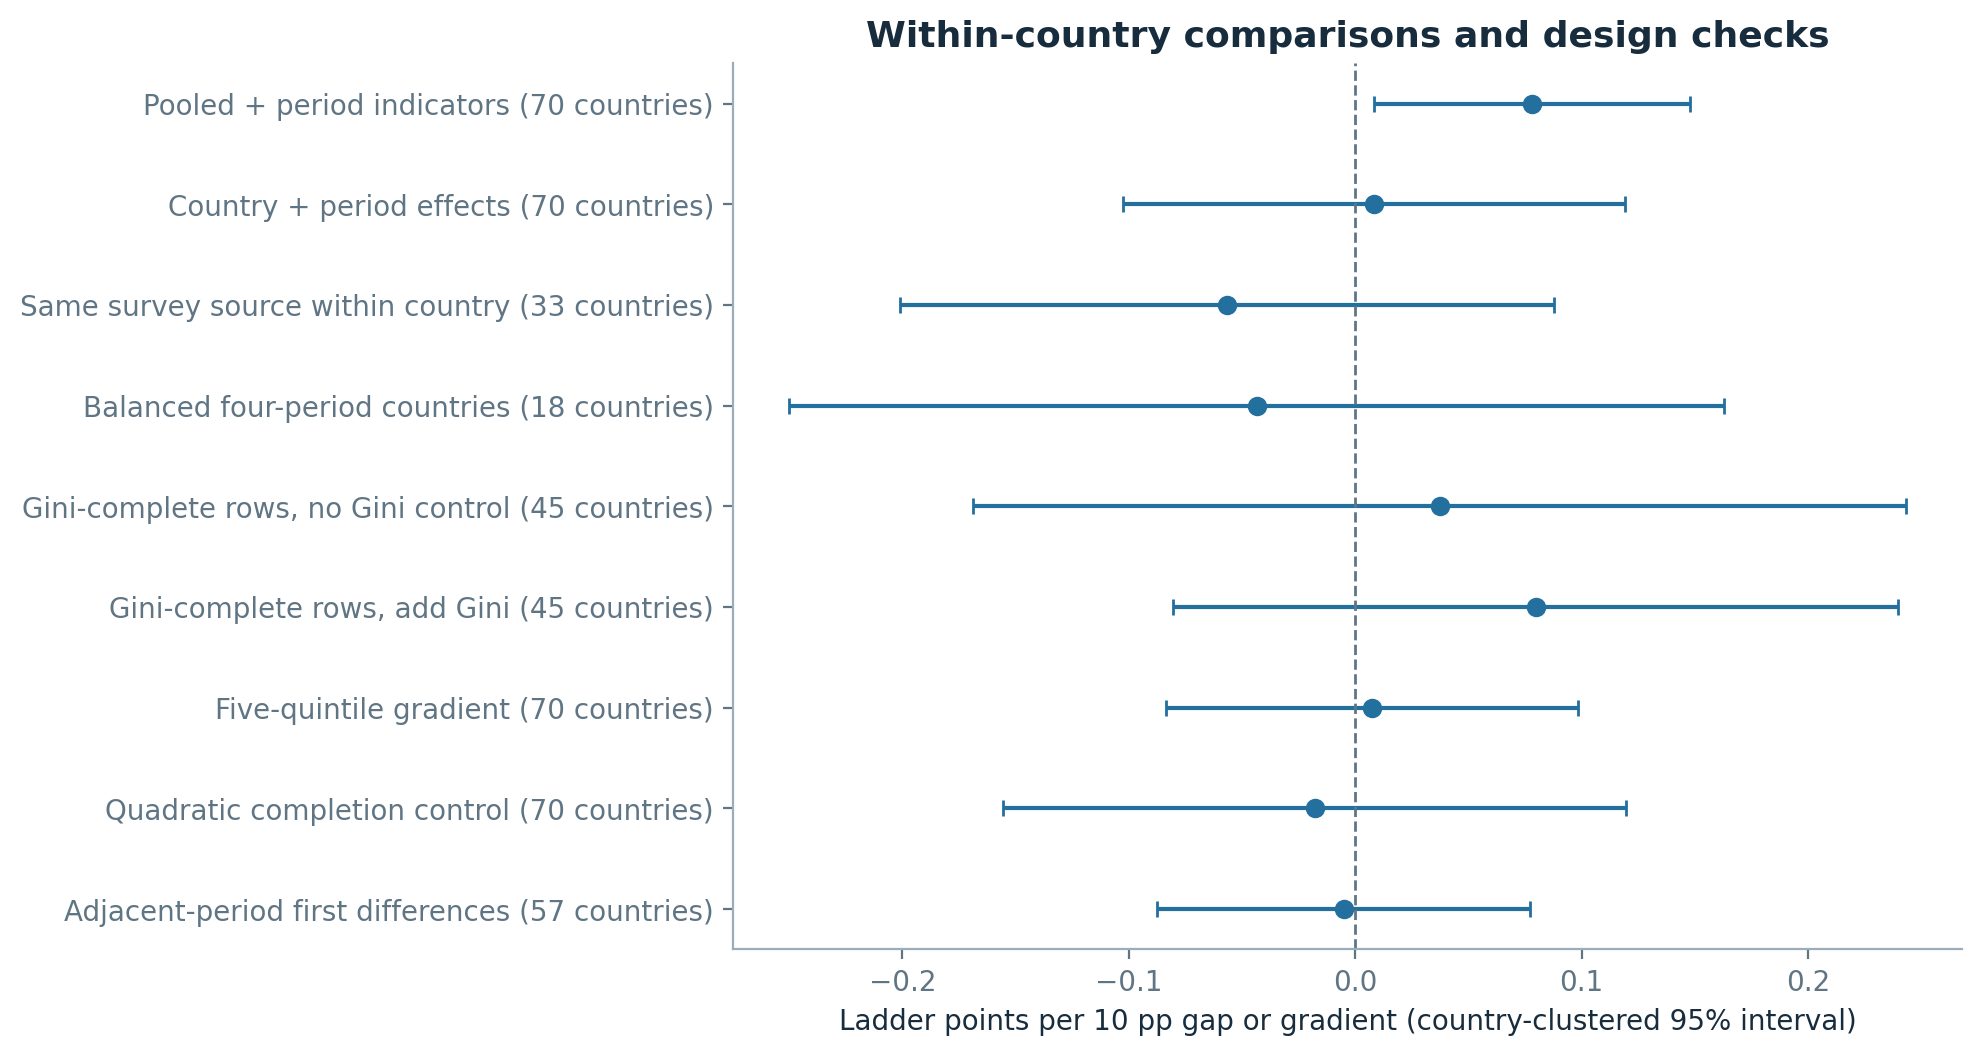

In [9]:
pm = panel_fit(panel)
display(table('panel_models.csv'))
display(table('panel_all_main_coefficients.csv'))
print('Inference reference degrees of freedom:', pm.df_resid_inference)
show('08_panel_estimates')

## 7. What variation supports the panel estimate?

Country effects remove persistent between-country differences. The resulting estimate depends on changes within observed histories, which contain much less variation and can be more sensitive to measurement error. The overall R² includes country intercepts and should not be interpreted as education's contribution.

Source-stable and balanced histories change the represented sample. The small balanced comparison has few country clusters. With and without Gini, the selected panel comparison uses exactly the same observations.

,variable,overall_sd,within_sd,within_variance_share
0,gap10,1.844929,0.679916,0.135816
1,log_gdp,0.954230,0.074854,0.006154
2,completion10,2.859149,0.446369,0.024373
3,ladder,1.021887,0.308679,0.091245


,model,term,country_periods,countries,estimate,se_cluster_country,ci_low,ci_high,p_value,df_inference,within_r2,overall_r2
0,Within/between with period indicators,gap10_between,198,70,0.086386,0.040161,0.006266,0.166505,0.034983,69,NaN,0.658486
1,Within/between with period indicators,gap10_within,198,70,0.039294,0.048929,-0.058316,0.136905,0.424680,69,NaN,0.658486


all_complete_country_periods                                                  226
all_complete_countries                                                         98
within_country_periods                                                        198
within_countries                                                               70
balanced_countries                                                             18
same_source_countries                                                          33
gini_complete_countries                                                        45
primary                         {'model': 'Country + period effects', 'term': ...
cluster_bootstrap               {'successful_draws': 2000, 'median': 0.0094117...
leave_one_country_beta_min                                              -0.004667
leave_one_country_beta_max                                               0.030481
interpretation                  Exploratory longitudinal association. Repeated...
dtype: object

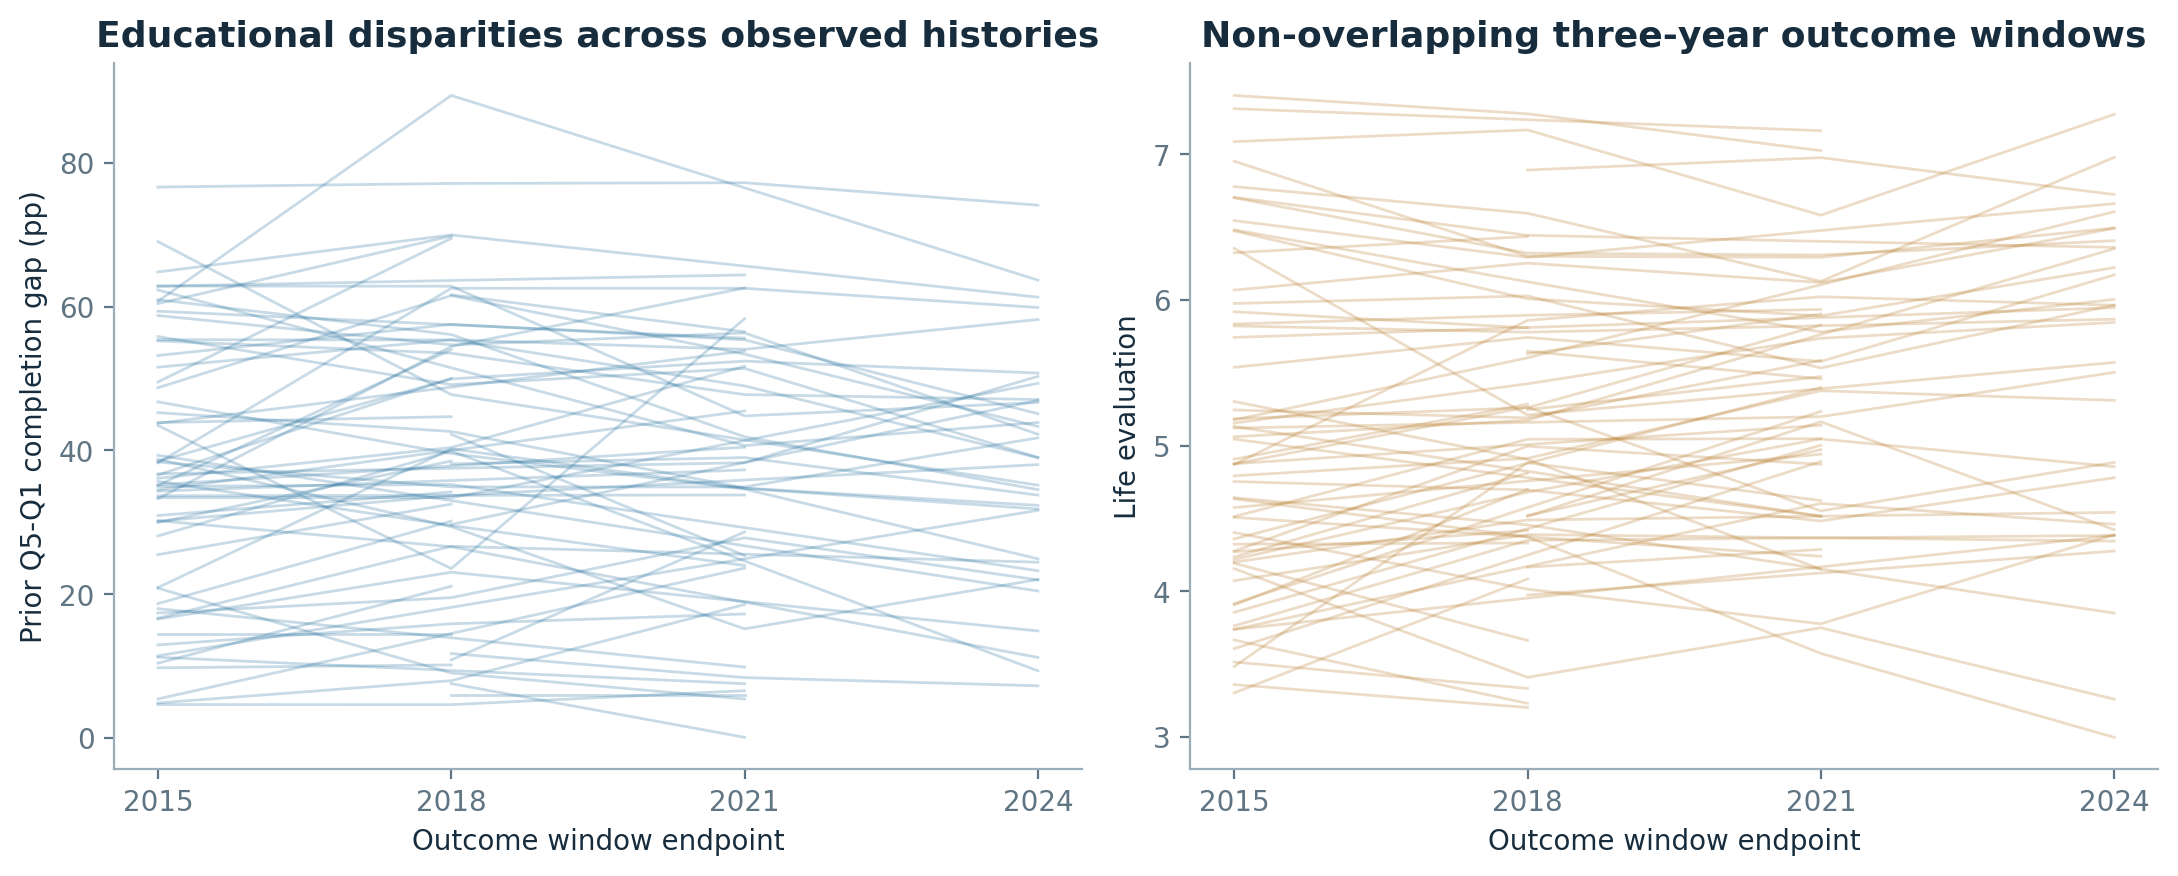

In [10]:
display(table('panel_identifying_variation.csv'))
display(table('panel_within_between.csv'))
display(pd.Series(panel_results))
show('09_panel_histories')

## 8. Incremental fit and paired resampling

Partial R² is the fraction of a reduced model's remaining squared error removed by a predictor. The two predictor contributions must be compared using the same resampled countries. Separate confidence-interval overlap is not the paired comparison.

Partial R² is bounded below by zero. Percentile bootstrap limits near that boundary are descriptive and must not be read as proof of nonzero population contribution. Panel resampling uses whole country histories. Neither empirical bootstrap reconstructs the original complex household-survey uncertainty.

In [11]:
display(table('partial_r2.csv'))
display(table('country_bootstrap_summary.csv'))
print('Country-history bootstrap:', panel_results['cluster_bootstrap'])

Country-history bootstrap: {'successful_draws': 2000, 'median': 0.00941179033036359, 'ci_low': -0.07630929046035263, 'ci_high': 0.09519648237883434, 'resampling_unit': 'Whole country histories, conditional on observed surveys and outcome aggregates'}


,predictor,partial_r2
0,gap10,0.021008
1,gini10,0.063109


,quantity,bootstrap_median,ci_low,ci_high,successful_draws
0,education_beta,0.056376,-0.029131,0.146935,2000
1,education_partial_r2,0.023960,0.000115,0.144786,2000
2,gini_partial_r2,0.066160,0.000846,0.231956,2000
3,partial_r2_difference,-0.035847,-0.214568,0.121148,2000


## 9. Prediction for held-out countries

All compared models share identical five-fold splits, repeated 20 times. The gap uses fixed arithmetic, so no learned preprocessing has leaked across folds. Scores describe interpolation to countries represented by this selected sample. They are not forecasts of future wellbeing or an untouched external validation.

Split-to-split variation describes re-partitioning the same observations. It is not a sampling confidence interval.

{'rmse_difference_full_minus_baseline': 0.0034874641362375113, 'split_sd': 0.00729413125643626, 'min_across_splits': -0.005657199147401704, 'max_across_splits': 0.025459218602869038, 'repeats_full_better': 7, 'repeats': 20, 'interpretation': 'Variation across reused random partitions, not a sampling confidence interval or independent hypothesis test.'}


,model,rmse_mean,rmse_split_sd,mae_mean,oof_r2_mean
0,Mean only,1.072569,0.011202,0.933561,-0.041439
1,Education gap,1.083342,0.016864,0.935395,-0.062598
2,Gini,1.077019,0.021563,0.927192,-0.050388
3,Prosperity,0.695575,0.010695,0.545368,0.561950
4,Prosperity + attainment,0.692103,0.014741,0.539026,0.566223
5,Baseline,0.684726,0.018268,0.535940,0.575317
6,Baseline + education gap,0.688214,0.019133,0.540373,0.570955


,model,loocv_rmse
0,Mean only,1.067492
1,Education gap,1.076774
2,Gini,1.069315
3,Prosperity,0.690840
4,Prosperity + attainment,0.685302
5,Baseline,0.676731
6,Baseline + education gap,0.680447


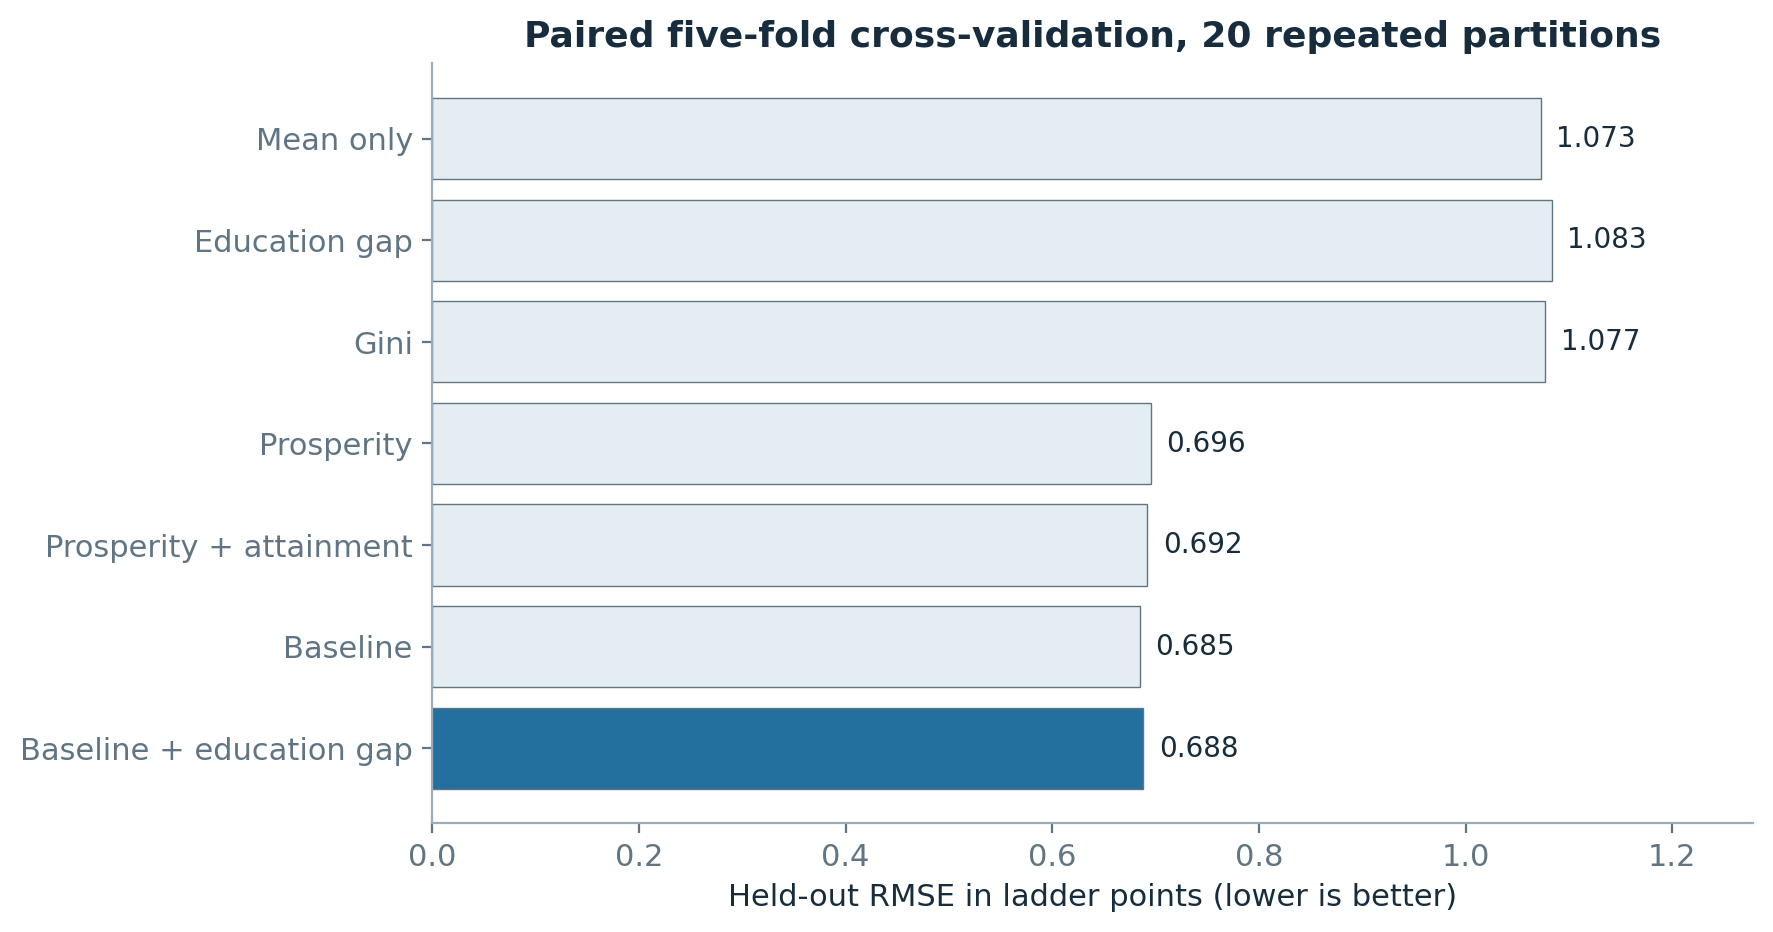

In [12]:
display(table('cv_summary.csv'))
display(table('loocv.csv'))
print(results['cv_paired'])
show('04_prediction')

In [13]:
predictions = table('cv_predictions.csv')
assert predictions.groupby(['repeat', 'iso_code']).fold.nunique().eq(1).all()
display(predictions.head(15))
display(table('region_transport.csv'))

,repeat,fold,model,iso_code,actual,predicted
0,0,0,Mean only,AUS,6.974,5.242481
1,0,0,Mean only,CHN,5.921,5.242481
2,0,0,Mean only,CIV,5.102,5.242481
3,0,0,Mean only,COD,3.469,5.242481
4,0,0,Mean only,CRI,7.274,5.242481
5,0,0,Mean only,DOM,5.846,5.242481
6,0,0,Mean only,GEO,5.400,5.242481
7,0,0,Mean only,MEX,6.979,5.242481
8,0,0,Mean only,MWI,3.260,5.242481
9,0,0,Mean only,RUS,5.945,5.242481


,held_out_region,n_test,model,rmse
0,Central and Southern Asia,7,Baseline,0.739353
1,Central and Southern Asia,7,Baseline + education gap,0.790914
2,Eastern and South-eastern Asia,7,Baseline,0.465114
3,Eastern and South-eastern Asia,7,Baseline + education gap,0.415879
4,Europe and Northern America,5,Baseline,0.459540
5,Europe and Northern America,5,Baseline + education gap,0.432701
6,Latin America and the Caribbean,16,Baseline,0.874091
7,Latin America and the Caribbean,16,Baseline + education gap,0.908329
8,Northern Africa and Western Asia,6,Baseline,1.016283
9,Northern Africa and Western Asia,6,Baseline + education gap,1.025356


## 10. The complete specification grid

Three measurements × three adjustment sets × two recency samples produce 18 exploratory specifications. All are reported in design order. Coefficients are shown over each exposure's IQR to share a readable outcome scale; the underlying constructs remain different. Holm-adjusted p-values account for this documented test family without retrospectively making the study confirmatory.

,model,label,term,n,estimate,se_hc3,ci_low,ci_high,p_value,r2,adj_r2
0,Primary specification,Primary specification,gap10,65,0.054028,0.047155,-0.040296,0.148352,0.256448,0.646146,0.622556
1,Education surveys from 2010 onward,Education surveys from 2010 onward,gap10,79,0.040277,0.038384,-0.036204,0.116758,0.297443,0.602544,0.581060
2,Education surveys from 2018 onward,Education surveys from 2018 onward,gap10,48,-0.005538,0.048483,-0.103313,0.092238,0.909594,0.720267,0.694245
3,Gini observations from 2020 onward,Gini observations from 2020 onward,gap10,47,0.039654,0.056575,-0.074519,0.153827,0.487226,0.662609,0.630477
4,DHS or MICS surveys only,DHS or MICS surveys only,gap10,38,0.048689,0.072060,-0.097919,0.195297,0.503959,0.601073,0.552719
5,Reported Q1 and Q5 n >= 100,Reported Q1 and Q5 n >= 100,gap10,34,0.002630,0.086087,-0.173439,0.178698,0.975841,0.540832,0.477499
6,Exclude Cook-flagged countries,Exclude Cook-flagged countries,gap10,59,0.051475,0.043306,-0.035348,0.138299,0.239782,0.737037,0.717558
7,Allow quadratic log prosperity,Allow quadratic log prosperity,gap10,65,0.061630,0.054983,-0.048392,0.171652,0.266879,0.647036,0.617124
8,Allow quadratic completion,Allow quadratic completion,gap10,65,0.110141,0.069129,-0.028186,0.248467,0.116445,0.650918,0.621334
9,Adjust for education survey age,Adjust for education survey age,gap10,65,0.048420,0.048288,-0.048204,0.145043,0.320082,0.649467,0.619761


,sample,n,measure,adjustment,estimate_per_iqr,ci_low_per_iqr,ci_high_per_iqr,iqr_exposure,p_value,max_leverage,p_holm_exploratory_family
0,primary,65,gap10,Unadjusted,-0.138268,-0.478361,0.201824,2.503000,4.195950e-01,0.086549,1.000000e+00
1,primary,65,gap10,Prosperity,0.134813,-0.089656,0.359281,2.503000,2.344923e-01,0.099367,1.000000e+00
2,primary,65,gap10,Prosperity + attainment + Gini,0.135232,-0.100862,0.371326,2.503000,2.564484e-01,0.199227,1.000000e+00
3,primary,65,relative_gap,Unadjusted,-1.401828,-1.763657,-1.039999,1.400780,1.008289e-10,0.051288,1.714092e-09
4,primary,65,relative_gap,Prosperity,-0.191903,-0.733066,0.349261,1.400780,4.810696e-01,0.127515,1.000000e+00
5,primary,65,relative_gap,Prosperity + attainment + Gini,0.713245,-0.364260,1.790751,1.400780,1.904989e-01,0.316337,1.000000e+00
6,primary,65,gradient10,Unadjusted,-0.081005,-0.433069,0.271060,3.245000,6.472515e-01,0.103181,1.000000e+00
7,primary,65,gradient10,Prosperity,0.143501,-0.092235,0.379236,3.245000,2.282743e-01,0.104282,1.000000e+00
8,primary,65,gradient10,Prosperity + attainment + Gini,0.143192,-0.106730,0.393114,3.245000,2.563188e-01,0.196817,1.000000e+00
9,expanded,79,gap10,Unadjusted,-0.133592,-0.455743,0.188559,2.741000,4.114975e-01,0.065134,1.000000e+00


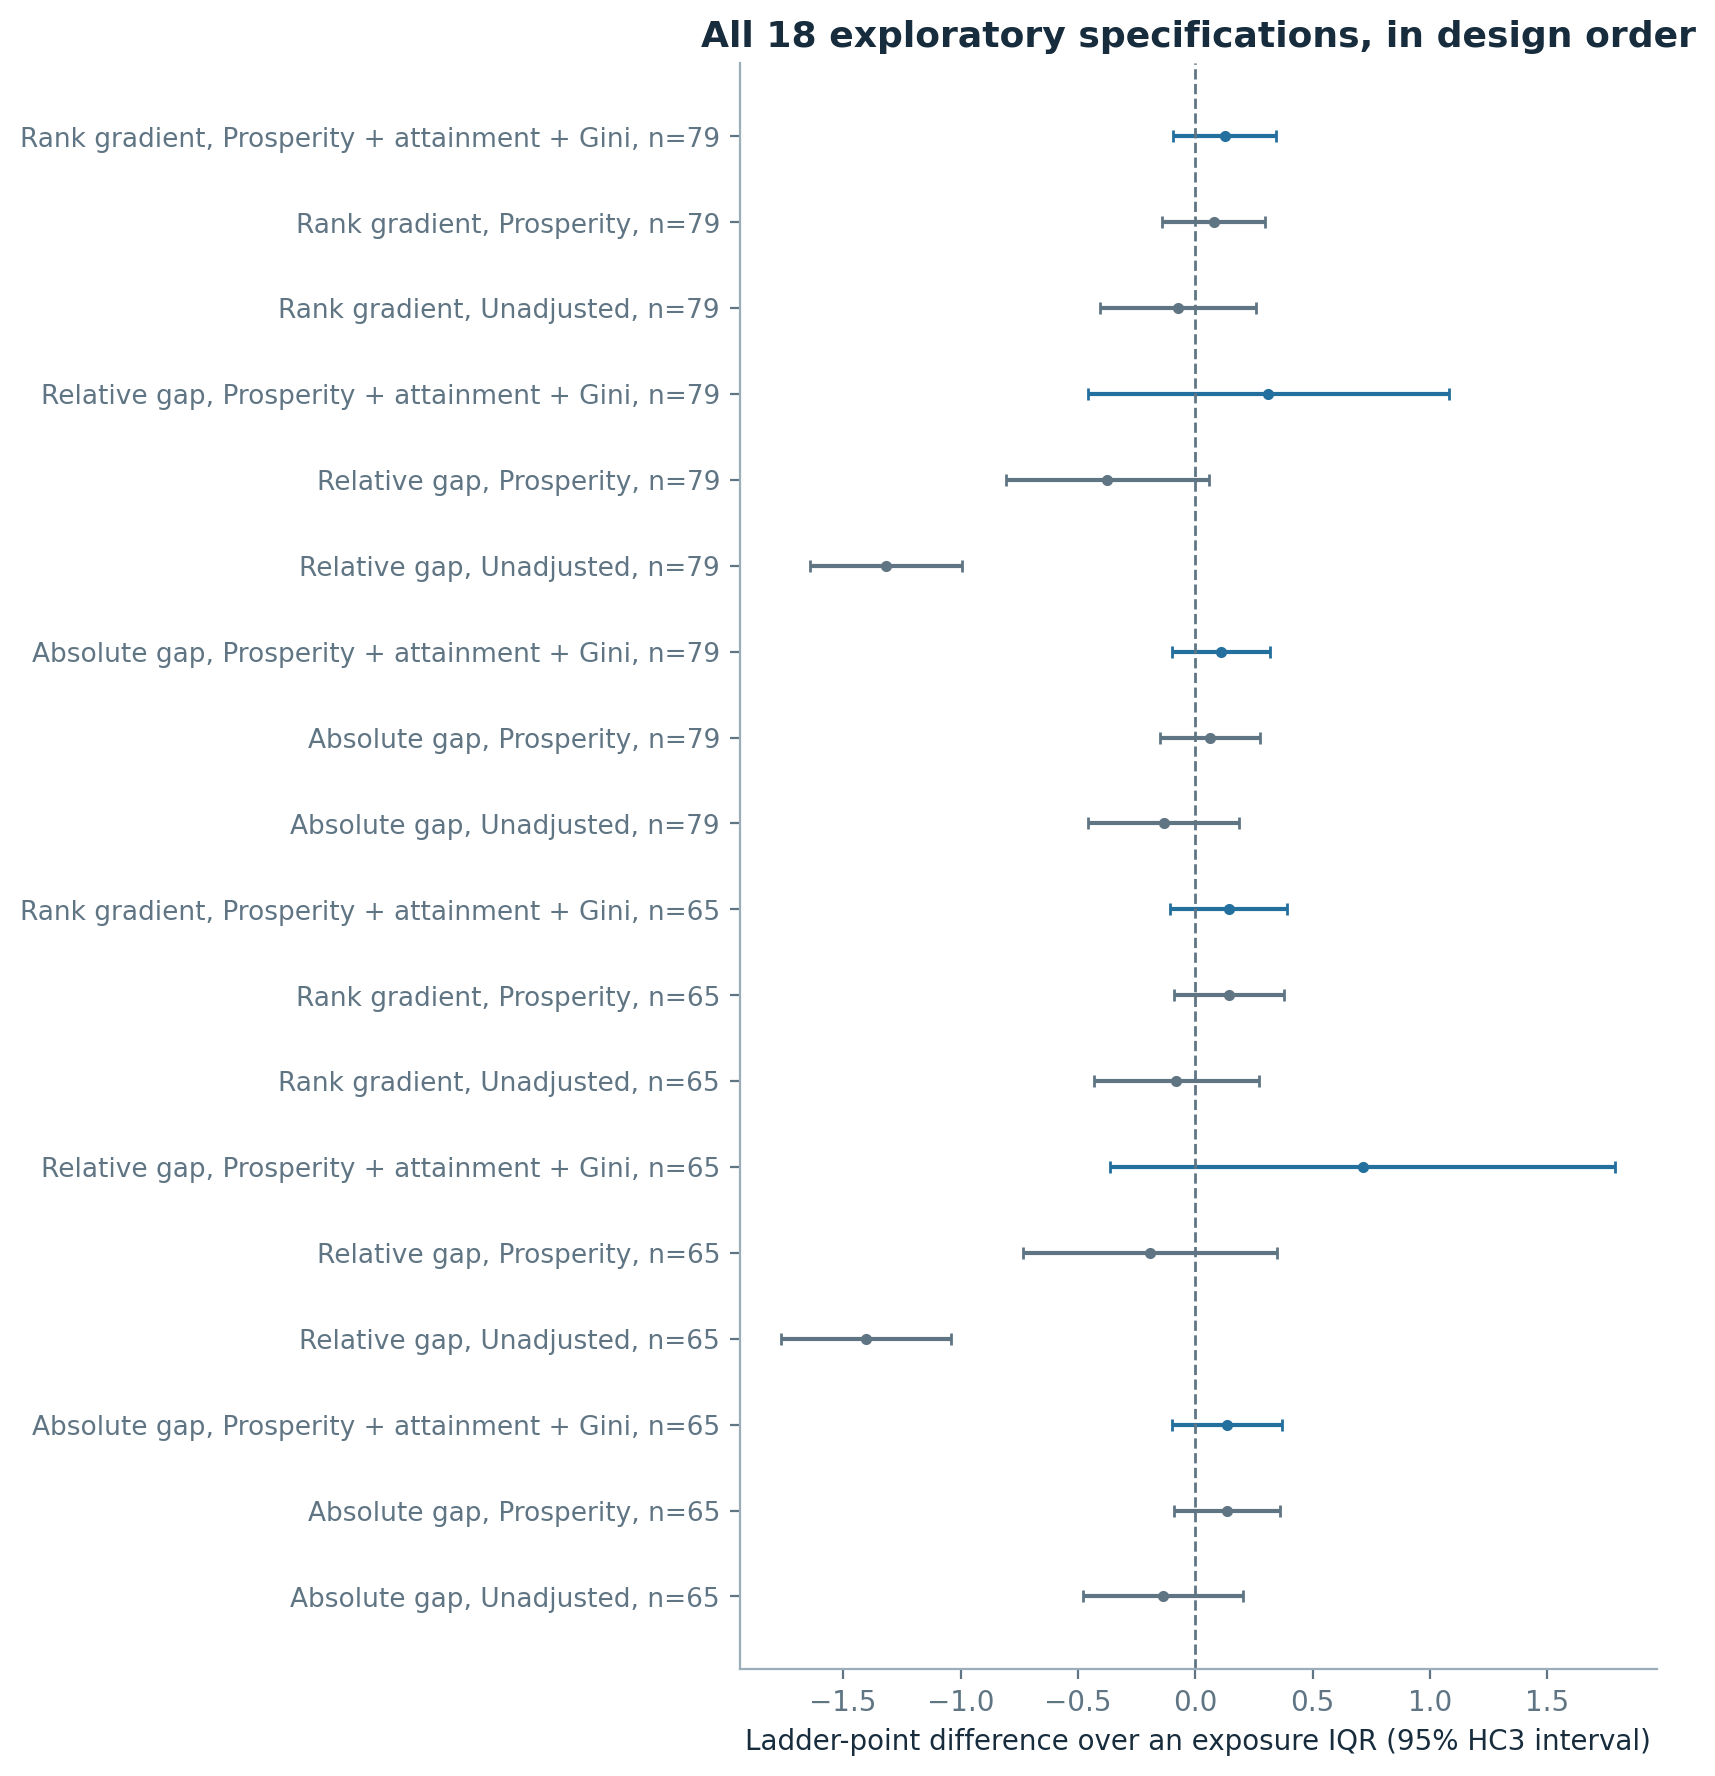

In [14]:
display(table('sensitivity.csv'))
display(table('specification_grid.csv'))
show('10_specification_grid', width=950)

## 11. A separate, schematic simulation

Generate prosperity z, completion midpoint `m = 0.2 + 0.6 logistic(z)`, and an independent absolute gap `d ~ Uniform(0.04, 0.16)`. Generate life evaluation as `5 + 0.9z + noise`. Relative disparity is `d/m`.

The relative measure can then have a strong negative unconditional association even though absolute disparity has no generated causal path to wellbeing. That unconditional association is real in this simulated population, not a statistical false positive for zero association. The experiment illustrates denominator coupling and the danger of a causal reading. Its parameters are not fitted to the real data.

,measure,adjusted_for_prosperity,mean_coefficient,negative_association_detection_rate,any_sign_detection_rate
0,Absolute gap,False,-0.020538,0.027,0.055
1,Absolute gap,True,0.000743,0.024,0.053
2,Relative gap,False,-5.435336,1.000,1.000
3,Relative gap,True,-0.006224,0.019,0.042


{'replications': 1000,
 'countries_per_replication': 150,
 'seed': 272728,
 'dgp': {'prosperity_z': 'N(0,1)',
  'completion_midpoint': '0.2 + 0.6 * logistic(z)',
  'absolute_gap': 'Uniform(0.04,0.16), independent of z and noise',
  'q1': 'midpoint - absolute_gap/2',
  'q5': 'midpoint + absolute_gap/2',
  'relative_gap': 'absolute_gap/midpoint',
  'life_evaluation': '5 + 0.9*z + Normal(0,0.7^2)'},
 'interpretation': 'A deliberately schematic example of denominator coupling. Both inequality measures are valid but answer different descriptive questions. A nonzero unconditional relative-gap association is real in this simulated population, so it is not a false rejection of zero association. It cannot be interpreted as an education-disparity treatment effect. The experiment is not fitted to or a validation of the empirical DGP.'}

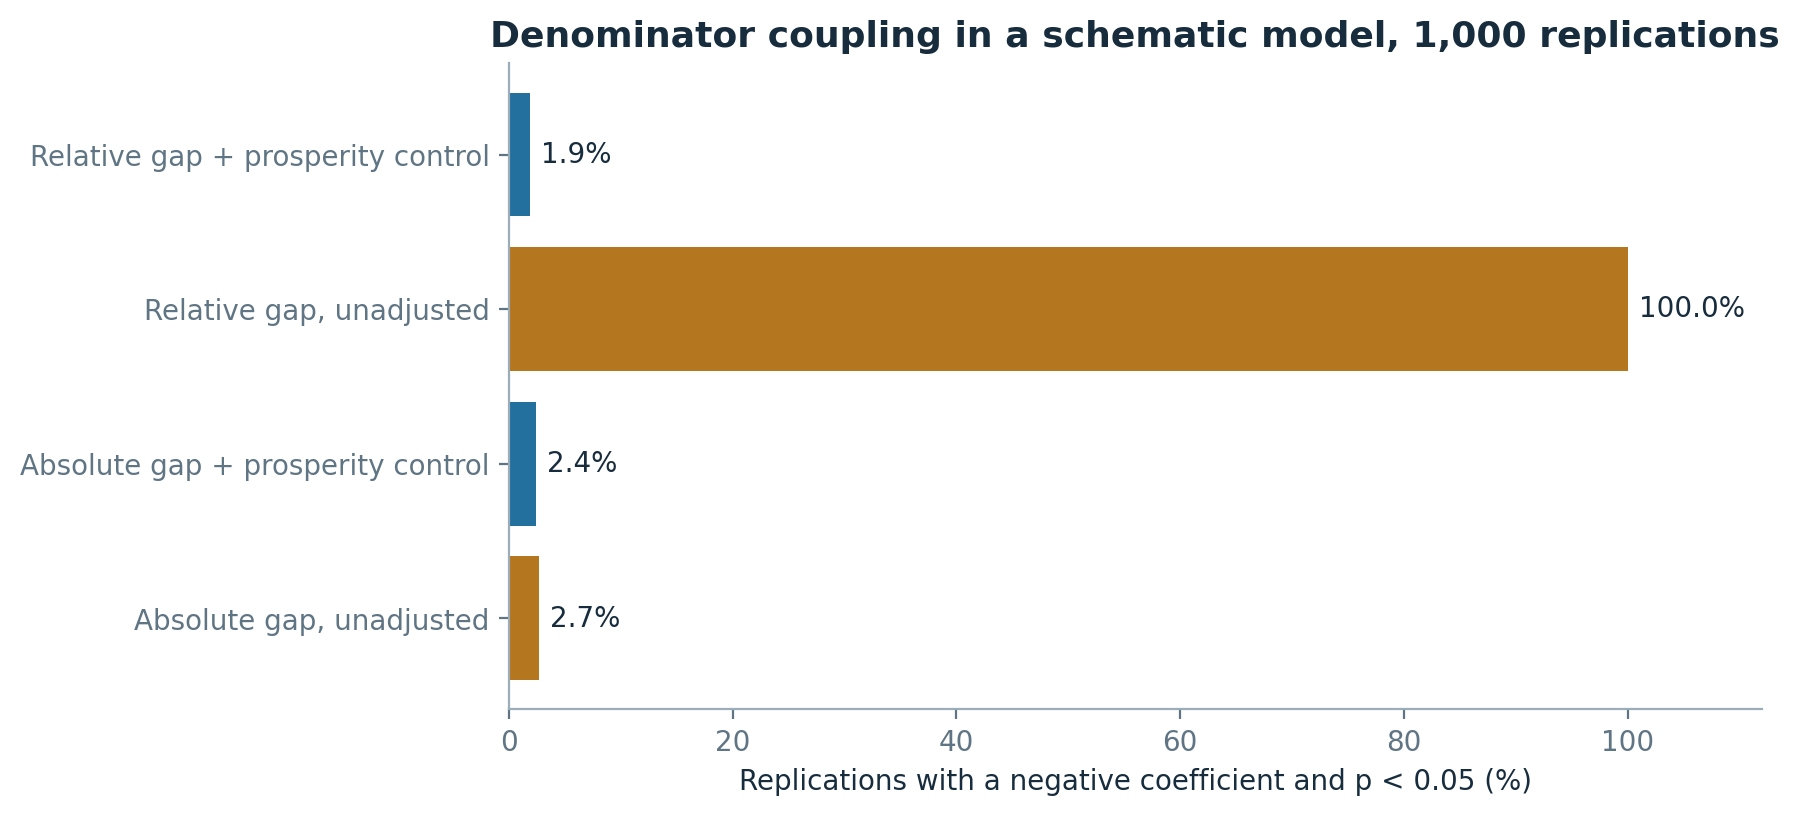

In [15]:
display(table('simulation_summary.csv'))
display(json.loads((PROJECT / 'outputs/simulation_design.json').read_text()))
show('11_measurement_simulation')

## 12. Scientific verification

The verification script independently reconstructs the HC3 and country-cluster covariance matrices, checks PRESS against explicit refits, audits all country splits and survey windows and checks same-country measurement comparisons. Passing these checks establishes computational consistency under the implemented design, not truth of the identifying assumptions.

In [16]:
runpy.run_module('src.verify', run_name='__main__')
display(json.loads((PROJECT / 'outputs/verification.json').read_text()))

PASS: Every frozen input matches its SHA-256 manifest
PASS: Country keys, source windows, gap units and complete-case contracts hold
PASS: OLS coefficients and HC3 covariance match independent matrix calculations
PASS: Every CV prediction is out of fold and comparisons share identical country splits
PASS: Analytic leave-one-out errors match explicit omitted-country refits
PASS: Panel outcomes and prior-education blocks are disjoint, with no reused surveys
PASS: Country-clustered covariance and G-1 reference df match independent calculations
PASS: All disparity measures use the same countries for comparison
PASS: Both empirical bootstrap analyses completed all 2,000 replications
PASS: All 18 documented specifications and multiplicity corrections are present


{'passed': True,
 'checks': ['Every frozen input matches its SHA-256 manifest',
  'Country keys, source windows, gap units and complete-case contracts hold',
  'OLS coefficients and HC3 covariance match independent matrix calculations',
  'Every CV prediction is out of fold and comparisons share identical country splits',
  'Analytic leave-one-out errors match explicit omitted-country refits',
  'Panel outcomes and prior-education blocks are disjoint, with no reused surveys',
  'Country-clustered covariance and G-1 reference df match independent calculations',
  'All disparity measures use the same countries for comparison',
  'Both empirical bootstrap analyses completed all 2,000 replications',
  'All 18 documented specifications and multiplicity corrections are present']}

## 13. What the evidence supports

The absolute completion gap has little stable incremental predictive value in the observed recent sample. Absolute and relative measures capture different information about attainment levels. The longitudinal estimates are also imprecise around zero.

This does not prove that educational equality lacks a causal effect or social value. Gaps are measured imperfectly, selection is substantial, household-survey uncertainty is incomplete, and time-varying confounding remains. A causal analysis requires a new design with defensible policy variation or comparable microdata, rather than simply adding an estimator.

Read the full paper in `outputs/Education_Disparities_Research_Paper.pdf`, the editable manuscript in `docs/research_paper.md`, the decision log in `docs/research_protocol.md`, and the detailed methods guide in `docs/methods_explained.md`. All third-party data retain their source terms.